# Queuing systems

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gstonge/csi4124-sys5110/blob/main/notebooks/queuing-system.ipynb)
[![Open in JupyterLite](https://jupyterlite.rtfd.io/en/latest/_static/badge.svg)](https://www.gstonge.ca/csi4124-sys5110/lite/notebooks/index.html?path=queuing-system.ipynb)

In this notebook, we discuss queuing systems in the context of discrete-event simulation. We use a very simple example: a gas station with one pump, where cars arrive at a constant rate and line up in front of the pump, waiting for their turn. We first explore the concept of a *stationary distribution* (steady state) using Gillespie's direct method. We then introduce a new stochastic simulation algorithm, the *event-scheduling* approach, which lets us simulate events whose inter-event times are not exponentially distributed.

In [1]:
import numpy as np
import heapq
import matplotlib.pyplot as plt
from scipy.special import gamma

## Gillespie's direct method

Let $n$ be the number of cars at the station, including the one at the pump. Cars arrive ($n \to n+1$) at rate $\alpha$ and, while the pump is busy ($n > 0$), the car being served leaves ($n \to n-1$) at rate $\beta$.

In [2]:
n = 1 # one car already at the pump
n_traj = [n]
rng = np.random.default_rng(42)
T = 5000
alpha = 0.2 #arrival rate of cars (# cars per min)
beta = 0.3 #service rate (# cars per min)
t = 0
t_traj = [t]

In [3]:
while t < T:
    #determine inter-event time
    service_rate = beta if n > 0 else 0
    total_rate = alpha + service_rate
    tau = rng.exponential(scale=1/(total_rate))
    t += tau
    #now we determine which event happens
    prob_arrival = alpha/(alpha + service_rate)
    if rng.random() < prob_arrival:
        n += 1
    else:
        n -= 1
    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

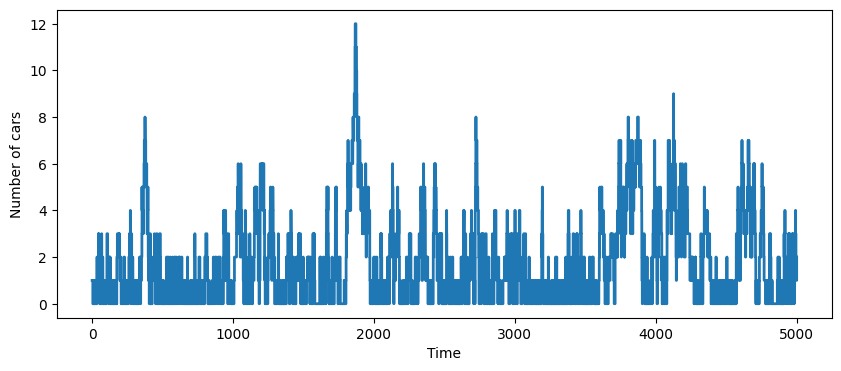

In [4]:
plt.subplots(figsize=(10, 4))
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

**Try these cases:**
- check what happens when $\beta < \alpha$;
- test a large initial condition ($n \gg 1$). What happens?

### Stationary distribution

Over a long time horizon, the trajectory keeps fluctuating within the same range of values. Let's sample this trajectory at regular time intervals of length $\Delta t = 1$ and extract the underlying distribution. We discard the first portion (up to $t = 200$) so that we only sample the "stable", long-term part of the trajectory; this discarded portion is called the *burn-in* or *warm-up* period.

**Note:** the sampling interval and the warm-up period are chosen arbitrarily for now; later, we will see how to guide these choices.

In [5]:
t_burn = 200
t_step = 1

In [6]:
n_chosen_samples = []
for t_chosen in range(t_burn,T,t_step):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    n_chosen_samples.append(n_traj[index])

We can compare this with what theory says about the *stationary distribution*, which is the fixed point of the master equation describing the system. For $\rho = \alpha/\beta < 1$, it is

$$
P_n^* = (1-\rho)\,\rho^n .
$$

In [7]:
nrange = np.arange(0,25)
rho = alpha/beta
Pn = (1-rho)*rho**nrange

mean = 1.6897916666666666  std = 1.9322428565263794


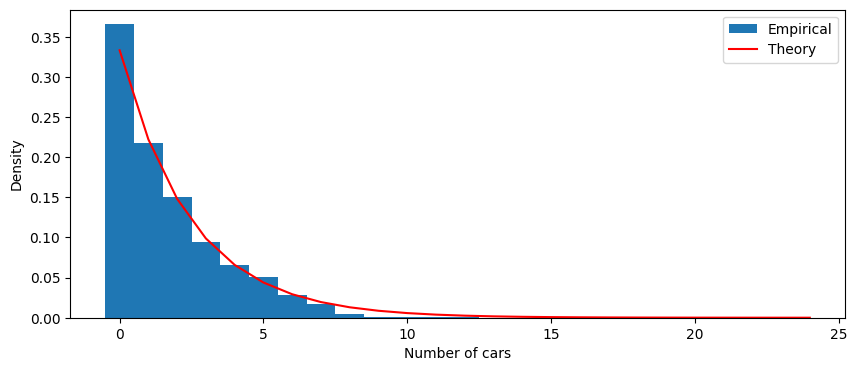

In [8]:
plt.subplots(figsize=(10, 4))
plt.hist(n_chosen_samples, bins=np.arange(max(n_chosen_samples)+2)-0.5, density=True, label='Empirical')
plt.plot(nrange,Pn, color='red', label='Theory')
plt.xlabel('Number of cars')
plt.ylabel('Density')
plt.legend()
print('mean =', np.mean(n_chosen_samples), ' std =', np.std(n_chosen_samples))

The two distributions agree well. What if, instead of sampling one trajectory at regular intervals, we generated many independent trajectories and sampled each one at a fixed time $t^*$, far enough in the future? Would the distribution look similar?

## Event-scheduling approach

### Exponential service time

Here we implement the alternative simulation procedure introduced in class, where we keep a *future-event list*, ordered by the execution time of the scheduled events. As a simple check, we first use exponential inter-event times, to match Gillespie's direct method.

In [9]:
t = 0
n = 1  # one car already at the pump
t_traj = [t]
n_traj = [n]

# future event list: entries are (event time, event type)
fel = []
heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))  # car already being served

In [10]:
while fel and fel[0][0] < T:
    t, event = heapq.heappop(fel)  # advance to the next event

    if event == "arrival":
        n += 1
        # schedule the next arrival
        heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
        # if the pump was free, the car starts service right away
        if n == 1:
            heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))

    else:  # departure
        n -= 1
        # if cars are waiting, the next one starts service
        if n > 0:
            heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))

    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

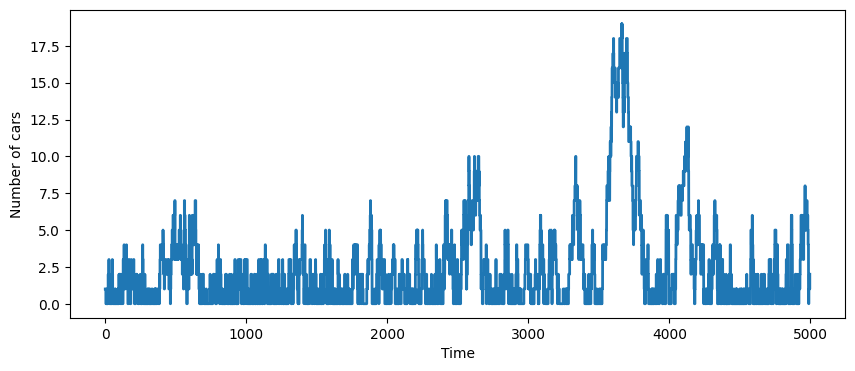

In [11]:
plt.subplots(figsize=(10, 4))
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

In [12]:
n_chosen_samples = []
for t_chosen in range(t_burn,T,t_step):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    n_chosen_samples.append(n_traj[index])

mean = 2.3697916666666665  std = 3.162627460925049


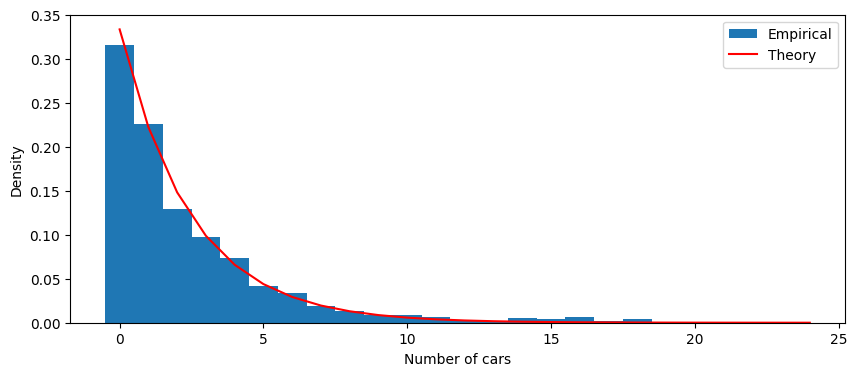

In [13]:
plt.subplots(figsize=(10, 4))
plt.hist(n_chosen_samples, bins=np.arange(max(n_chosen_samples)+2)-0.5, density=True, label='Empirical')
plt.plot(nrange,Pn, color='red', label='Theory')
plt.xlabel('Number of cars')
plt.ylabel('Density')
plt.legend()
print('mean =', np.mean(n_chosen_samples), ' std =', np.std(n_chosen_samples))

Although there is variability (randomness means we do not get exactly the same trajectory), the stationary distribution matches qualitatively.

### Weibull service time

We now consider a service time at the pump that is not exponentially distributed: a Weibull distribution, which is more concentrated around its mean. We keep the same mean service time, $1/\beta$.

In [14]:
k = 6.0  # Weibull shape (k = 1 gives back the exponential)
weibull_scale = (1/beta) / gamma(1 + 1/k)  # so the mean service time is 1/beta

def service_time():
    return weibull_scale * rng.weibull(k)

In [15]:
T = 5000

alpha = 0.2  # arrival rate of cars (# cars per min)
beta = 0.3   # service rate (# cars per min)

t = 0
n = 1  # one car already at the pump
t_traj = [t]
n_traj = [n]

# future event list: entries are (event time, event type)
fel = []
heapq.heappush(fel, (rng.exponential(1/alpha), "arrival"))
heapq.heappush(fel, (service_time(), "departure"))  # car already being served

In [16]:
while fel and fel[0][0] < T:
    t, event = heapq.heappop(fel)  # advance to the next event

    if event == "arrival":
        n += 1
        # schedule the next arrival
        heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
        # if the pump was free, the car starts service right away
        if n == 1:
            heapq.heappush(fel, (t + service_time(), "departure"))

    else:  # departure
        n -= 1
        # if cars are waiting, the next one starts service
        if n > 0:
            heapq.heappush(fel, (t + service_time(), "departure"))

    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

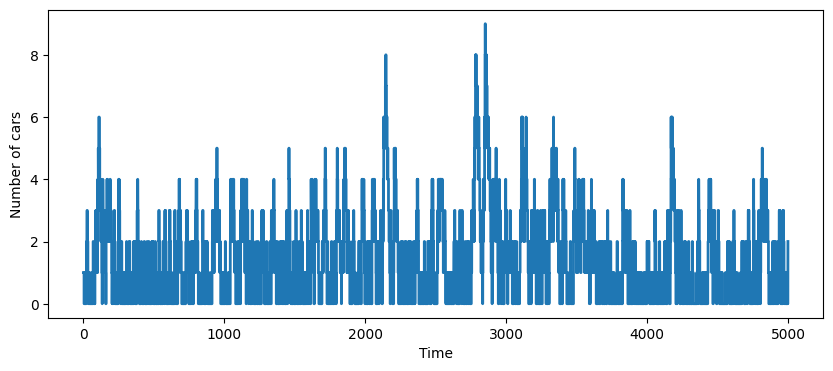

In [17]:
plt.subplots(figsize=(10, 4))
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

We can already see a difference in the shape of the trajectory: long lines of cars are less frequent.

In [18]:
n_chosen_samples = []
for t_chosen in range(t_burn,T,t_step):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    n_chosen_samples.append(n_traj[index])

mean = 1.3920833333333333  std = 1.384294282196608


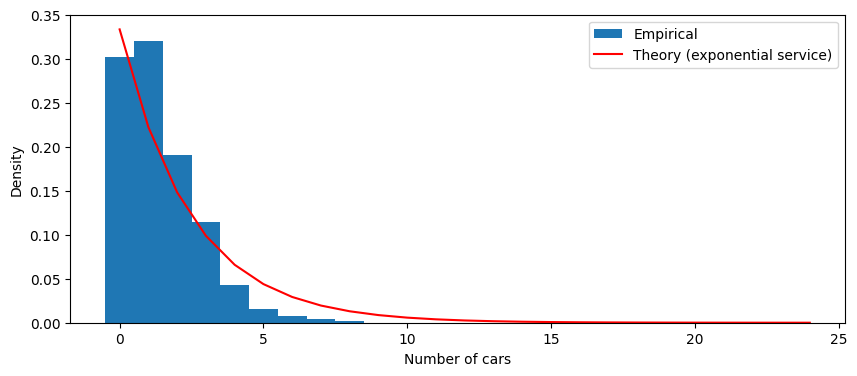

In [19]:
plt.subplots(figsize=(10, 4))
plt.hist(n_chosen_samples, bins=np.arange(max(n_chosen_samples)+2)-0.5, density=True, label='Empirical')
plt.plot(nrange,Pn, color='red', label='Theory (exponential service)')
plt.xlabel('Number of cars')
plt.ylabel('Density')
plt.legend()
print('mean =', np.mean(n_chosen_samples), ' std =', np.std(n_chosen_samples))

Does the stationary distribution of the exponential case still fit? Why?